# 🍽️ Zomato Bangalore Restaurant Data Analysis

**Author:** Nikhil
**Dataset:** Zomato Restaurants Dataset (Bangalore) — sourced from Kaggle
**Goal:** Clean the raw Zomato export and answer real business questions about restaurant trends, pricing, ratings, and locality performance in Bangalore.

This notebook covers:
1. Data loading & cleaning
2. Exploratory Data Analysis (EDA)
3. Visualizations
4. Key insights summary


## 1. Setup & Load Data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

# NOTE: update this path if you're running the notebook yourself
RAW_PATH = "Zomato_Restaurants_Dataset_export_2025-09-28_20-08-54.csv"
df = pd.read_csv(RAW_PATH)
df.head()


,Unnamed: 0,restaurant name,restaurant type,rate (out of 5),num of ratings,avg cost (two people),online_order,table booking,cuisines type,Unnamed: 9,area,local address
0,0,#FeelTheROLL,Quick Bites,3.4,7,200,No,No,Fast Food,0,Bellandur,Bellandur
1,1,#L-81 Cafe,Quick Bites,3.9,48,400,Yes,No,"Fast Food, Beverages",1,"Byresandra,Tavarekere,Madiwala",HSR
2,2,#refuel,Cafe,3.7,37,400,Yes,No,"Cafe, Beverages",2,Bannerghatta Road,Bannerghatta Road
3,3,'@ Biryani Central,Casual Dining,2.7,135,550,Yes,No,"Biryani, Mughlai, Chinese",3,Marathahalli,Marathahalli
4,4,'@ The Bbq,Casual Dining,2.8,40,700,Yes,No,"BBQ, Continental, North Indian, Chinese, Bever...",4,Bellandur,Bellandur


In [2]:
print("Shape:", df.shape)
df.info()


Shape: (7105, 12)
<class 'pandas.DataFrame'>
RangeIndex: 7105 entries, 0 to 7104
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             7105 non-null   int64  
 1   restaurant name        7105 non-null   str    
 2   restaurant type        7105 non-null   str    
 3   rate (out of 5)        7105 non-null   float64
 4   num of ratings         7105 non-null   int64  
 5   avg cost (two people)  7105 non-null   int64  
 6   online_order           7105 non-null   str    
 7   table booking          7105 non-null   str    
 8   cuisines type          7105 non-null   str    
 9   Unnamed: 9             7105 non-null   int64  
 10  area                   7105 non-null   str    
 11  local address          7105 non-null   str    
dtypes: float64(1), int64(4), str(7)
memory usage: 666.2 KB


## 2. Data Cleaning

The raw export had a few issues to fix before analysis:
- Two junk index columns (`Unnamed: 0`, `Unnamed: 9`)
- Messy column names with inconsistent casing/spacing
- `rating` and `avg_cost_for_two` had `0` values used to represent *missing* data (a restaurant can't really have a 0/5 rating)
- `online_order` / `table_booking` stored as Yes/No text instead of booleans
- `restaurant_type` and `cuisines` sometimes list multiple values per restaurant (e.g. `"Casual Dining, Bar"`), which makes simple grouping harder


In [3]:
# Drop junk columns
df = df.drop(columns=["Unnamed: 0", "Unnamed: 9"])

# Rename to clean, consistent column names
df = df.rename(columns={
    "restaurant name": "restaurant_name",
    "restaurant type": "restaurant_type",
    "rate (out of 5)": "rating",
    "num of ratings": "num_ratings",
    "avg cost (two people)": "avg_cost_for_two",
    "online_order": "online_order",
    "table booking": "table_booking",
    "cuisines type": "cuisines",
    "area": "area",
    "local address": "local_address",
})

# Strip whitespace from text columns
for c in df.select_dtypes(include="object").columns:
    df[c] = df[c].astype(str).str.strip()

# Remove exact duplicate rows
before = len(df)
df = df.drop_duplicates()
print(f"Removed {before - len(df)} duplicate rows")


Removed 0 duplicate rows


/tmp/ipykernel_204/2202475029.py:19: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for c in df.select_dtypes(include="object").columns:


In [4]:
# Treat 0 as missing for rating & cost (not a real value)
df.loc[df["rating"] == 0, "rating"] = pd.NA
df.loc[df["avg_cost_for_two"] == 0, "avg_cost_for_two"] = pd.NA

# Convert Yes/No to boolean
for c in ["online_order", "table_booking"]:
    df[c] = df[c].str.strip().str.lower().map({"yes": True, "no": False})

df.isnull().sum()


restaurant_name      0
restaurant_type      0
rating              68
num_ratings          0
avg_cost_for_two    57
online_order         0
table_booking        0
cuisines             0
area                 0
local_address        0
dtype: int64

In [5]:
# Create helper columns: primary cuisine/type (first item listed), and a cost bucket
df["primary_cuisine"] = df["cuisines"].apply(lambda x: x.split(",")[0].strip() if pd.notna(x) else x)
df["primary_type"] = df["restaurant_type"].apply(lambda x: x.split(",")[0].strip() if pd.notna(x) else x)

def cost_bucket(cost):
    if pd.isna(cost):
        return "Unknown"
    elif cost <= 300:
        return "Budget (<=300)"
    elif cost <= 600:
        return "Mid-range (301-600)"
    elif cost <= 1000:
        return "Premium (601-1000)"
    else:
        return "Fine Dine (1000+)"

df["cost_bucket"] = df["avg_cost_for_two"].apply(cost_bucket)
df.head()


,restaurant_name,restaurant_type,rating,num_ratings,avg_cost_for_two,online_order,table_booking,cuisines,area,local_address,primary_cuisine,primary_type,cost_bucket
0,#FeelTheROLL,Quick Bites,3.4,7,200.0,False,False,Fast Food,Bellandur,Bellandur,Fast Food,Quick Bites,Budget (<=300)
1,#L-81 Cafe,Quick Bites,3.9,48,400.0,True,False,"Fast Food, Beverages","Byresandra,Tavarekere,Madiwala",HSR,Fast Food,Quick Bites,Mid-range (301-600)
2,#refuel,Cafe,3.7,37,400.0,True,False,"Cafe, Beverages",Bannerghatta Road,Bannerghatta Road,Cafe,Cafe,Mid-range (301-600)
3,'@ Biryani Central,Casual Dining,2.7,135,550.0,True,False,"Biryani, Mughlai, Chinese",Marathahalli,Marathahalli,Biryani,Casual Dining,Mid-range (301-600)
4,'@ The Bbq,Casual Dining,2.8,40,700.0,True,False,"BBQ, Continental, North Indian, Chinese, Bever...",Bellandur,Bellandur,BBQ,Casual Dining,Premium (601-1000)


## 3. Exploratory Data Analysis

Now that the data is clean, let's answer specific questions rather than plotting everything randomly.


### Q1. Which cuisines are most common?

In [6]:
top_cuisines = df["primary_cuisine"].value_counts().head(10)
top_cuisines


primary_cuisine
North Indian    1943
South Indian     841
Chinese          455
Cafe             449
Biryani          408
Fast Food        395
Continental      253
Bakery           235
Desserts         209
Andhra           193
Name: count, dtype: int64

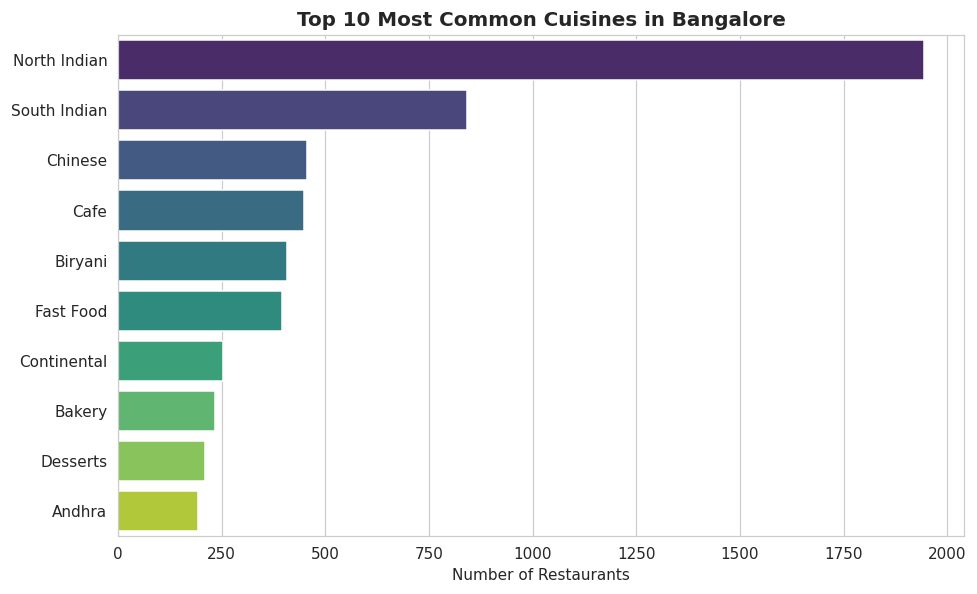

In [7]:
plt.figure(figsize=(9, 5.5))
sns.barplot(x=top_cuisines.values, y=top_cuisines.index, hue=top_cuisines.index, palette="viridis", legend=False)
plt.title("Top 10 Most Common Cuisines in Bangalore", fontsize=13, fontweight="bold")
plt.xlabel("Number of Restaurants")
plt.ylabel("")
plt.tight_layout()
plt.show()


### Q2. Which localities have the most restaurants?

In [8]:
top_localities = df["local_address"].value_counts().head(10)
top_localities


local_address
Whitefield           459
BTM                  458
Electronic City      404
Marathahalli         381
HSR                  378
Indiranagar          292
JP Nagar             283
Bannerghatta Road    257
Jayanagar            218
Bellandur            199
Name: count, dtype: int64

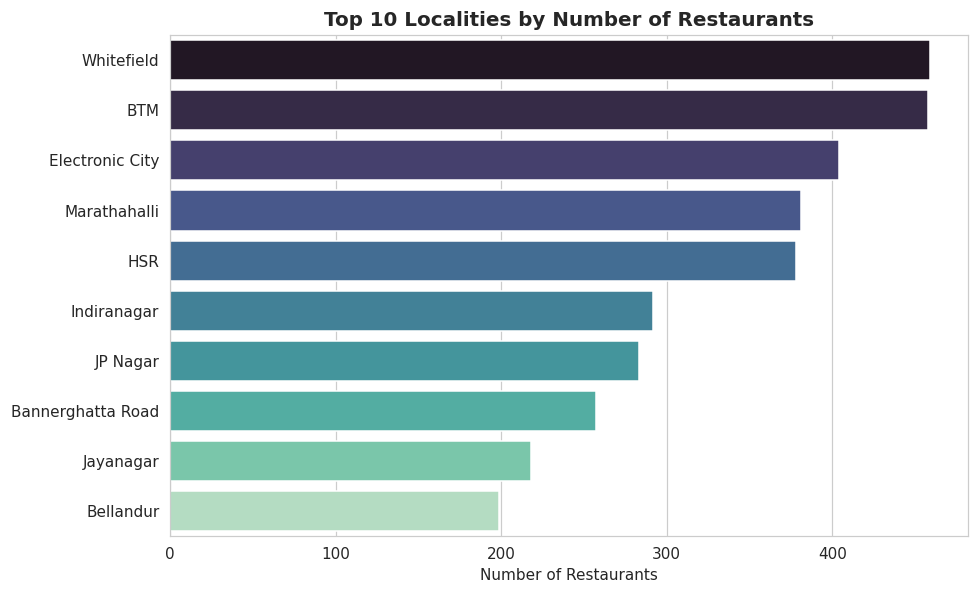

In [9]:
plt.figure(figsize=(9, 5.5))
sns.barplot(x=top_localities.values, y=top_localities.index, hue=top_localities.index, palette="mako", legend=False)
plt.title("Top 10 Localities by Number of Restaurants", fontsize=13, fontweight="bold")
plt.xlabel("Number of Restaurants")
plt.ylabel("")
plt.tight_layout()
plt.show()


### Q3. Which restaurant types dominate the market?

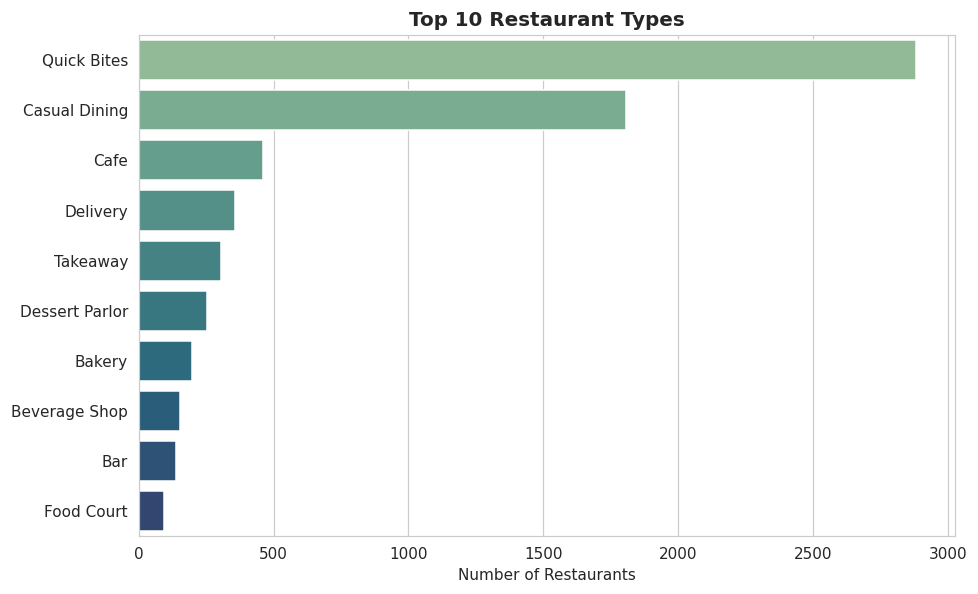

In [10]:
top_types = df["primary_type"].value_counts().head(10)
plt.figure(figsize=(9, 5.5))
sns.barplot(x=top_types.values, y=top_types.index, hue=top_types.index, palette="crest", legend=False)
plt.title("Top 10 Restaurant Types", fontsize=13, fontweight="bold")
plt.xlabel("Number of Restaurants")
plt.ylabel("")
plt.tight_layout()
plt.show()


### Q4. Does offering online ordering correlate with higher ratings?

In [11]:
online_stats = df.groupby("online_order")["rating"].agg(["mean", "median", "count"])
online_stats


,mean,median,count
online_order,,,
False,3.471924,3.5,3316
True,3.551975,3.6,3721


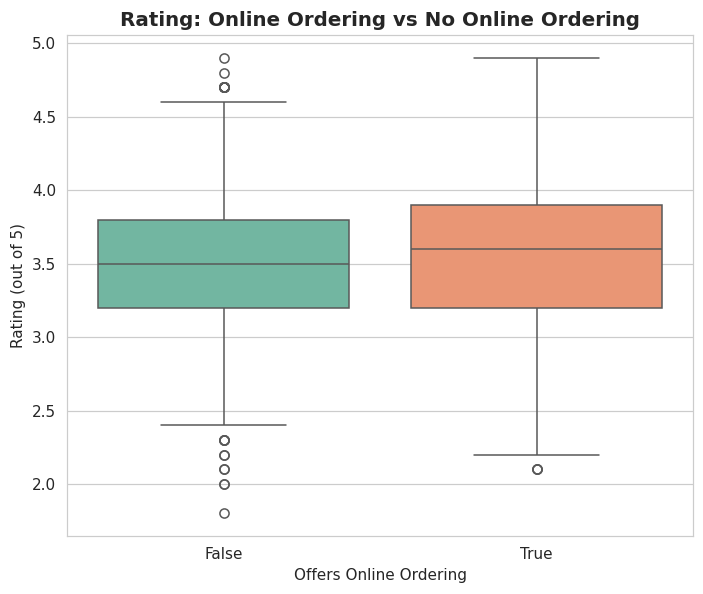

In [12]:
plt.figure(figsize=(6.5, 5.5))
sns.boxplot(data=df, x="online_order", y="rating", hue="online_order", palette="Set2", legend=False)
plt.title("Rating: Online Ordering vs No Online Ordering", fontsize=13, fontweight="bold")
plt.xlabel("Offers Online Ordering")
plt.ylabel("Rating (out of 5)")
plt.tight_layout()
plt.show()


### Q5. Does table booking relate to cost and rating?

In [13]:
booking_stats = df.groupby("table_booking")[["rating", "avg_cost_for_two"]].mean()
booking_stats


,rating,avg_cost_for_two
table_booking,,
False,3.452566,444.144829
True,4.036022,1354.905914


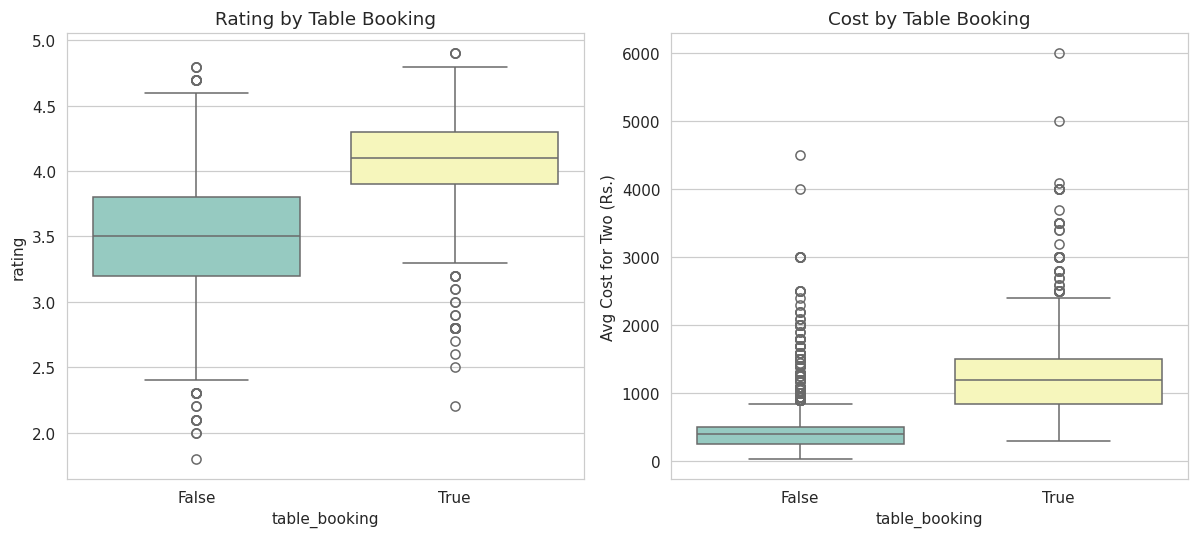

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
sns.boxplot(data=df, x="table_booking", y="rating", hue="table_booking", palette="Set3", legend=False, ax=axes[0])
axes[0].set_title("Rating by Table Booking")
sns.boxplot(data=df, x="table_booking", y="avg_cost_for_two", hue="table_booking", palette="Set3", legend=False, ax=axes[1])
axes[1].set_title("Cost by Table Booking")
axes[1].set_ylabel("Avg Cost for Two (Rs.)")
plt.tight_layout()
plt.show()


### Q6. Is there a relationship between cost and rating?

In [15]:
print("Correlation (cost vs rating):", df["avg_cost_for_two"].corr(df["rating"]).round(3))
df.groupby("cost_bucket")["rating"].mean().sort_values()


Correlation (cost vs rating): 0.376


cost_bucket
Budget (<=300)         3.394188
Mid-range (301-600)    3.459041
Unknown                3.507547
Premium (601-1000)     3.637354
Fine Dine (1000+)      4.026435
Name: rating, dtype: float64

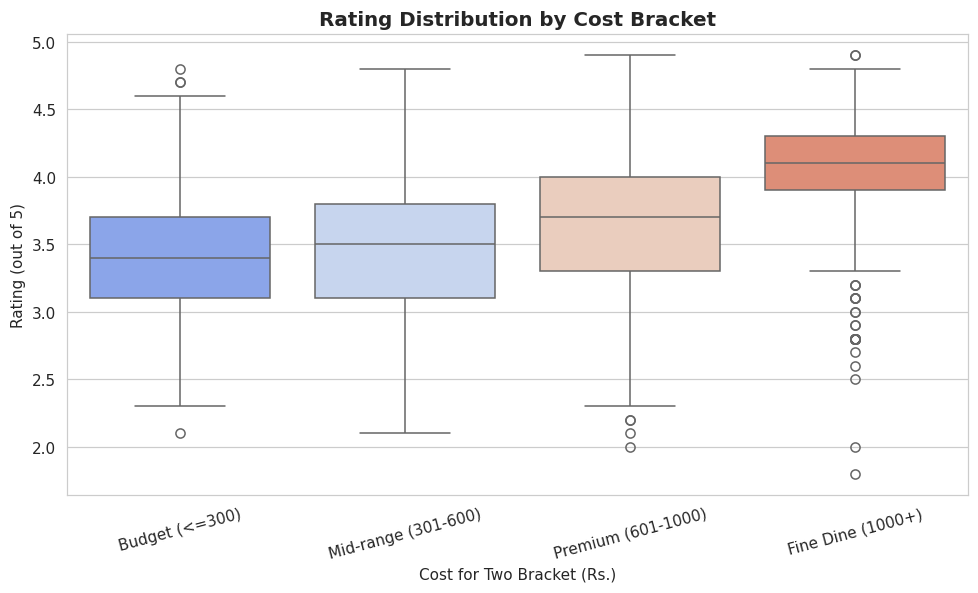

In [16]:
order = ["Budget (<=300)", "Mid-range (301-600)", "Premium (601-1000)", "Fine Dine (1000+)"]
plot_df = df[df["cost_bucket"].isin(order)]
plt.figure(figsize=(9, 5.5))
sns.boxplot(data=plot_df, x="cost_bucket", y="rating", order=order, hue="cost_bucket", palette="coolwarm", legend=False)
plt.title("Rating Distribution by Cost Bracket", fontsize=13, fontweight="bold")
plt.xlabel("Cost for Two Bracket (Rs.)")
plt.ylabel("Rating (out of 5)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


### Q7. Which localities have the highest average rating? (min. 30 restaurants)

In [17]:
locality_avg = df.groupby("local_address").filter(lambda x: len(x) >= 30) \
                 .groupby("local_address")["rating"].mean().sort_values(ascending=False)
locality_avg.head(10)


local_address
Lavelle Road             4.063158
Church Street            3.851613
Koramangala 5th Block    3.818012
MG Road                  3.795238
Residency Road           3.792308
Richmond Road            3.776667
Koramangala 4th Block    3.749231
Koramangala 7th Block    3.718841
Seshadripuram            3.707692
Cunningham Road          3.686667
Name: rating, dtype: float64

### Q8. Which locality offers the best 'value for money' (high rating relative to cost)?

In [18]:
value_df = df.groupby("local_address").filter(lambda x: len(x) >= 30) \
              .groupby("local_address").agg(
                  avg_rating=("rating", "mean"),
                  avg_cost=("avg_cost_for_two", "mean"),
                  count=("restaurant_name", "count")
              )
value_df["value_score"] = value_df["avg_rating"] / (value_df["avg_cost"] / 100)
value_df.sort_values("value_score", ascending=False).head(10)


,avg_rating,avg_cost,count,value_score
local_address,,,,
Basavanagudi,3.574219,333.521127,142,1.071662
Ejipura,3.380000,336.250000,41,1.005204
Shivajinagar,3.439394,356.060606,33,0.965957
Banashankari,3.485393,379.943820,178,0.917344
Kumaraswamy Layout,3.400000,375.961538,52,0.904348
Vijay Nagar,3.535714,393.414634,42,0.898725
Thippasandra,3.346667,374.444444,45,0.893769
BTM,3.393679,380.853392,458,0.891072
Jeevan Bhima Nagar,3.523529,397.307692,52,0.886852


### Q9. Correlation heatmap across numeric fields

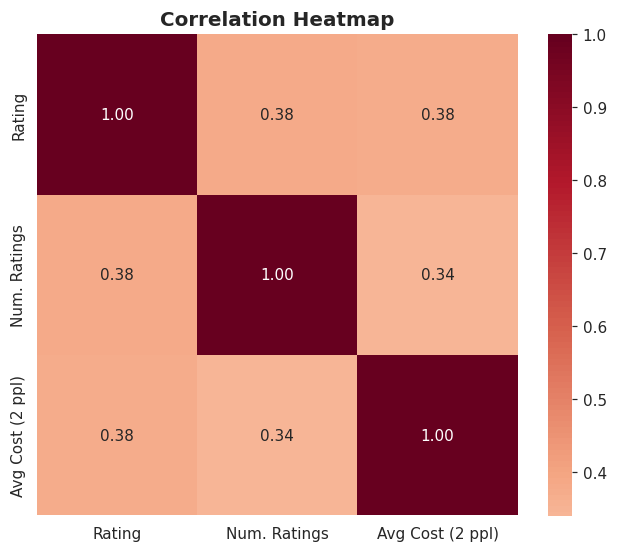

In [19]:
corr_cols = df[["rating", "num_ratings", "avg_cost_for_two"]].copy()
corr_cols.columns = ["Rating", "Num. Ratings", "Avg Cost (2 ppl)"]
plt.figure(figsize=(6, 5))
sns.heatmap(corr_cols.corr(), annot=True, cmap="RdBu_r", center=0, fmt=".2f", square=True)
plt.title("Correlation Heatmap", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


### Q10. Which cuisines have the highest average rating? (min. 50 restaurants)

In [20]:
cuisine_avg = df.groupby("primary_cuisine").filter(lambda x: len(x) >= 50) \
                .groupby("primary_cuisine")["rating"].mean().sort_values(ascending=False)
cuisine_avg.head(10)


primary_cuisine
American       3.979630
Asian          3.947273
Italian        3.818750
Continental    3.815538
Finger Food    3.753933
Seafood        3.716071
Cafe           3.709577
Desserts       3.608213
Chinese        3.513747
Street Food    3.503731
Name: rating, dtype: float64

## 4. Key Insights

1. **North Indian is king** — it's the most common primary cuisine by a wide margin (~1,940 restaurants), followed by South Indian (~840) and Chinese (~455). Bangalore's restaurant scene is dominated by a handful of cuisine types rather than being evenly spread.

2. **"Quick Bites" is the dominant format**, not fine dining — nearly 40% of all restaurants are Quick Bites or Casual Dining, confirming that Bangalore's food scene leans casual/affordable rather than upscale.

3. **Online ordering has only a small rating edge** — restaurants offering online ordering average ~3.55★ vs ~3.47★ for those that don't (~2.3% higher). Offering delivery doesn't guarantee better ratings; food quality still dominates.

4. **Table booking is a strong luxury signal** — restaurants offering table booking average **4.04★** vs **3.45★** for those that don't, and their average cost for two is roughly **3x higher** (₹1,355 vs ₹444). This is one of the clearest patterns in the dataset — table booking is a proxy for upscale, well-rated restaurants.

5. **Cost and rating are moderately correlated (r ≈ 0.38)** — pricier restaurants do tend to be rated higher, but it's far from a guarantee. Plenty of budget restaurants still score well, meaning price isn't the deciding factor.

6. **Premium localities lead on quality, not just quantity** — Lavelle Road (4.06★ avg), Church Street, and Koramangala 5th Block have the highest average ratings, all upscale central Bangalore neighborhoods, while high-volume outer localities like Whitefield and BTM have more restaurants but average ratings closer to the city median.

7. **Basavanagudi offers the best value-for-money** — high average rating relative to its low average cost, making it a standout compared to pricier "high-rating" areas like Lavelle Road.

8. **Popularity (number of ratings) correlates with quality (r ≈ 0.38)** — well-established, frequently-reviewed restaurants tend to have modestly higher ratings, likely reflecting consistency over time.

9. **Only 10.5% of restaurants offer table booking**, while 52.5% offer online ordering — showing Bangalore's restaurant market is optimized far more for delivery/convenience than for dine-in reservations.


## 5. Conclusion

This analysis shows Bangalore's restaurant scene is primarily a casual, delivery-first market dominated by North Indian and South Indian food, where **table booking availability is the single strongest visible signal of a high-rated, high-cost restaurant**, while online ordering has a much smaller effect. Central, upscale localities out-rate high-volume suburban ones, but some suburbs (like Basavanagudi) punch above their price point.

**Possible extensions:** predict rating from restaurant attributes (ML), sentiment analysis if review text were available, or scrape live Swiggy data to compare against this Zomato snapshot.
